In [3]:
# 1. IMPORT LIBRARIES AND SET PATHS

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path.cwd()
RESULTS_DIR = DATA_DIR.parent / "Results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

AIR_FILE = DATA_DIR / "AirQuality_AllStations.csv"
IMD_FILE = DATA_DIR / "IMD_Clean.csv"

print("Working directory:", DATA_DIR)
print("Air-quality file exists:", AIR_FILE.exists())
print("IMD file exists:", IMD_FILE.exists())

if not AIR_FILE.exists() or not IMD_FILE.exists():
    raise FileNotFoundError(
        "Required CSV files were not found. Keep this notebook in the same "
        "folder as AirQuality_AllStations.csv and IMD_Clean.csv."
    )


Working directory: C:\Users\shaur\Desktop\Projects\Diwali_AQ\QGIS\Data\processed
Air-quality file exists: True
IMD file exists: True


In [4]:
# 2. LOAD AND CHECK AIR-QUALITY DATA

df = pd.read_csv(AIR_FILE)

df["from_time"] = pd.to_datetime(df["from_time"], errors="coerce")
df["to_time"] = pd.to_datetime(df["to_time"], errors="coerce")

pollutants = ["PM2.5", "PM10", "NO2"]
stations = ["Dwarka", "IGI", "NSIT"]

print("Dataset shape:", df.shape)
print("\nRecords per station:")
display(df["station"].value_counts())

print("\nMissing pollutant values by station:")
display(df.groupby("station")[pollutants].apply(lambda x: x.isna().sum()))

print("\nDate range:", df["from_time"].min(), "to", df["from_time"].max())
print("Duplicate rows:", df.duplicated().sum())


Dataset shape: (573, 10)

Records per station:


station
Dwarka    191
IGI       191
NSIT      191
Name: count, dtype: int64


Missing pollutant values by station:


,PM2.5,PM10,NO2
station,,,
Dwarka,10,16,0
IGI,6,7,0
NSIT,7,9,0



Date range: 2025-10-18 00:00:00 to 2025-10-25 22:00:00
Duplicate rows: 0


Station-wise pollutant statistics:


PM2.5                                         PM10                  \
        count    mean  median     std    min     max count    mean  median   
station                                                                      
Dwarka    181  169.19  144.00  103.30  55.00  774.00   175  371.92  316.00   
IGI       185  131.97  112.21   90.95  47.44  822.15   184  306.78  275.20   
NSIT      184  117.95   94.76  108.44  21.30  891.60   182  310.66  280.56   

                                  NO2                                        
            std     min     max count    mean  median    std    min     max  
station                                                                      
Dwarka   171.21  138.00  997.00   191   74.51   67.85  30.42  23.20  159.25  
IGI      133.46  123.34  975.03   191  126.95  122.14  48.83  35.21  266.74  
NSIT     147.67   69.68  821.70   191   72.55   70.50  15.59  46.19  122.27

,date,station,PM25_mean,PM10_mean,PM25_count,PM10_count
0,2025-10-18,Dwarka,133.38,412.48,24,23
1,2025-10-18,IGI,100.30,301.09,24,24
2,2025-10-18,NSIT,67.97,158.80,24,24
3,2025-10-19,Dwarka,164.12,418.00,24,21
4,2025-10-19,IGI,123.12,331.63,24,24
5,2025-10-19,NSIT,101.74,323.28,24,24
6,2025-10-20,Dwarka,227.41,428.80,22,20
7,2025-10-20,IGI,197.73,366.64,24,23
8,2025-10-20,NSIT,200.34,506.13,24,23
9,2025-10-21,Dwarka,255.06,432.53,17,17


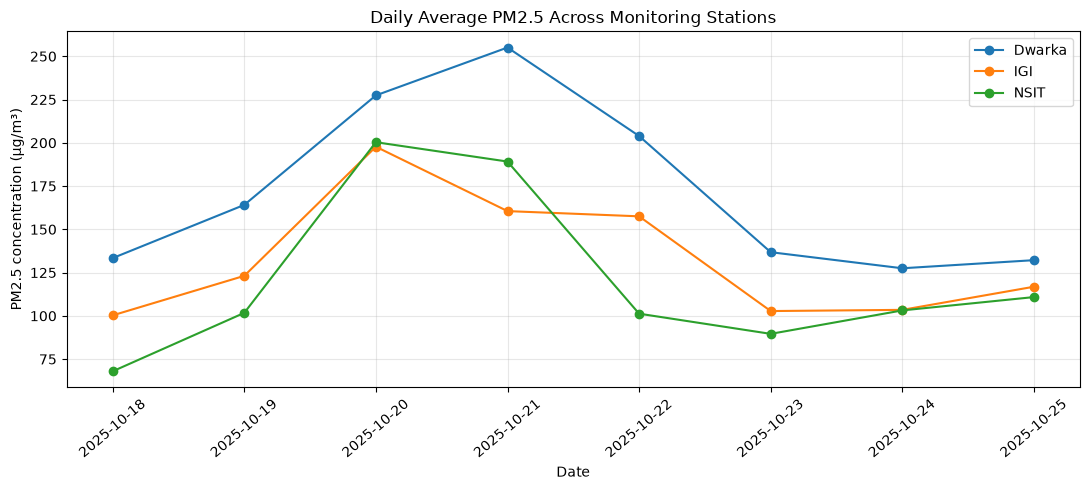

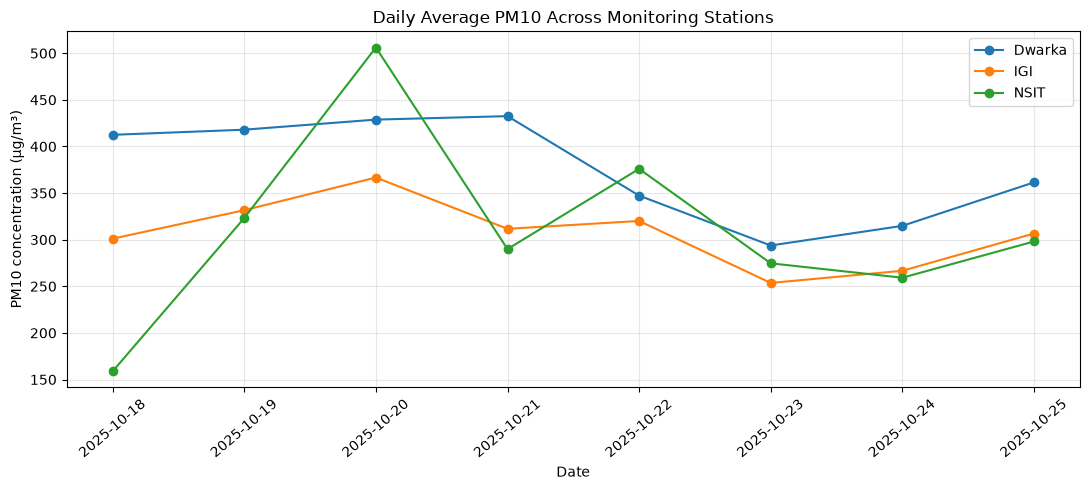

In [5]:
# 3. DESCRIPTIVE STATISTICS AND DAILY POLLUTION TRENDS

stats = df.groupby("station")[pollutants].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

print("Station-wise pollutant statistics:")
display(stats)

df["date"] = df["from_time"].dt.date

daily = df.groupby(["date", "station"]).agg(
    PM25_mean=("PM2.5", "mean"),
    PM10_mean=("PM10", "mean"),
    PM25_count=("PM2.5", "count"),
    PM10_count=("PM10", "count")
).reset_index()

display(daily.round(2))

for pollutant_col, title, ylabel, filename in [
    ("PM25_mean", "Daily Average PM2.5 Across Monitoring Stations",
     "PM2.5 concentration (µg/m³)", "Daily_PM25_Trends.png"),
    ("PM10_mean", "Daily Average PM10 Across Monitoring Stations",
     "PM10 concentration (µg/m³)", "Daily_PM10_Trends.png")
]:
    fig, ax = plt.subplots(figsize=(11, 5))
    for station in stations:
        part = daily[daily["station"] == station]
        ax.plot(part["date"], part[pollutant_col], marker="o", label=station)
    ax.set(title=title, xlabel="Date", ylabel=ylabel)
    ax.tick_params(axis="x", rotation=40)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

daily.to_csv(TABLES_DIR / "Daily_Pollution_Summary.csv", index=False)


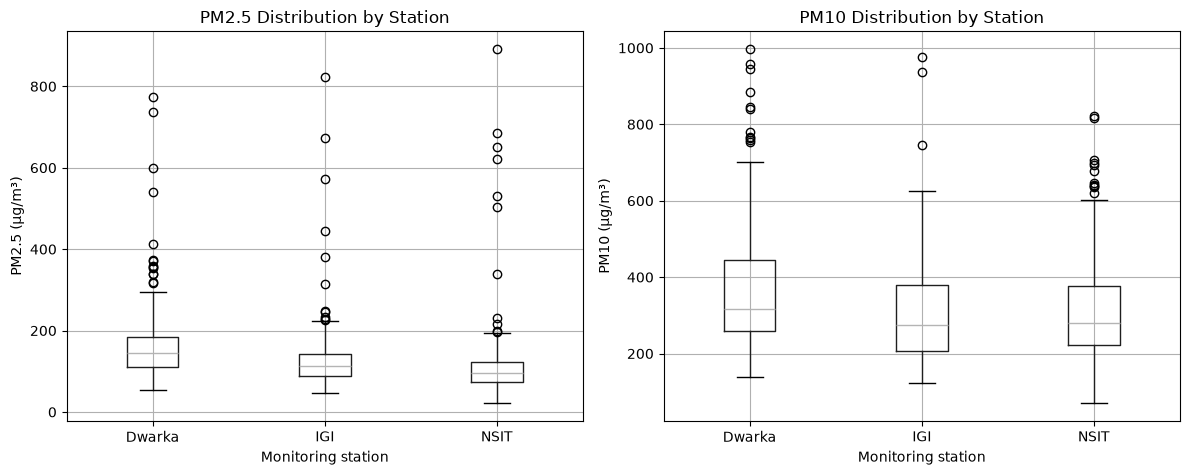

,PM2.5,PM10,NO2
station,,,
Dwarka,169.19,371.92,74.51
IGI,131.97,306.78,126.95
NSIT,117.95,310.66,72.55


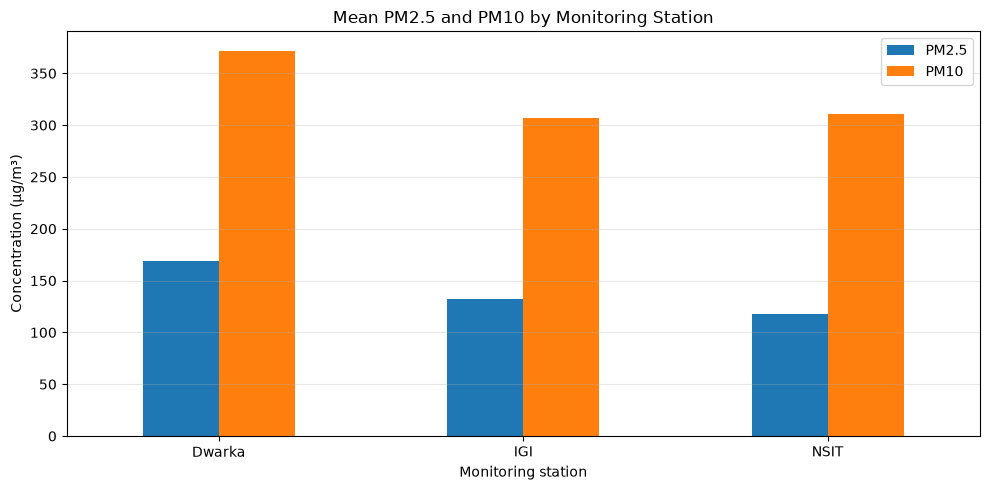

In [6]:
# 4. POLLUTANT DISTRIBUTION BY STATION

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df.boxplot(column="PM2.5", by="station", ax=axes[0])
axes[0].set_title("PM2.5 Distribution by Station")
axes[0].set_xlabel("Monitoring station")
axes[0].set_ylabel("PM2.5 (µg/m³)")

df.boxplot(column="PM10", by="station", ax=axes[1])
axes[1].set_title("PM10 Distribution by Station")
axes[1].set_xlabel("Monitoring station")
axes[1].set_ylabel("PM10 (µg/m³)")

plt.suptitle("")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "Pollutant_Distributions_by_Station.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Dynamic station-wise mean comparison
station_means = df.groupby("station")[["PM2.5", "PM10", "NO2"]].mean().reindex(stations)
display(station_means.round(2))
station_means.to_csv(TABLES_DIR / "Station_Wise_Pollution_Means.csv")

ax = station_means[["PM2.5", "PM10"]].plot(
    kind="bar", figsize=(10, 5), rot=0
)
ax.set_title("Mean PM2.5 and PM10 by Monitoring Station")
ax.set_xlabel("Monitoring station")
ax.set_ylabel("Concentration (µg/m³)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "Station_Wise_Pollution_Comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()


In [7]:
# 5. LOAD AND CHECK METEOROLOGICAL DATA

imd = pd.read_csv(IMD_FILE)
imd["time"] = pd.to_datetime(imd["time"], errors="coerce")

print("IMD dataset shape:", imd.shape)
print("Date range:", imd["time"].min(), "to", imd["time"].max())
print("\nMissing values:")
display(imd.isna().sum())

print("\nCalm wind observations:", (imd["wspd"] == 0).sum())

weather_daily = imd.assign(date=imd["time"].dt.date).groupby("date").agg(
    Temperature=("temp", "mean"),
    Humidity=("rhum", "mean"),
    WindSpeed=("wspd", "mean"),
    Pressure=("pres", "mean"),
    Rainfall=("prcp", "sum")
).round(2)

display(weather_daily)


IMD dataset shape: (192, 12)
Date range: 2025-10-18 00:30:00 to 2025-10-25 23:30:00

Missing values:


time      0
temp      0
dwpt      0
rhum      0
prcp      0
snow    192
wdir      0
wspd      0
wpgt    192
pres      0
tsun    192
coco      0
dtype: int64


Calm wind observations: 73


,Temperature,Humidity,WindSpeed,Pressure,Rainfall
date,,,,,
2025-10-18,26.00,66.38,3.38,1012.50,0.0
2025-10-19,26.33,67.38,2.04,1011.83,0.0
2025-10-20,26.54,66.17,3.62,1012.21,0.0
2025-10-21,26.79,63.58,4.17,1013.46,0.3
2025-10-22,25.50,70.71,5.12,1013.92,0.0
2025-10-23,24.17,64.21,5.04,1013.33,0.0
2025-10-24,23.58,61.71,3.00,1013.08,0.0
2025-10-25,24.04,59.83,1.67,1012.58,0.0


In [8]:
# 6. ALIGN WEATHER WITH AIR-QUALITY OBSERVATIONS

# CPCB records represent hourly intervals; IMD observations are at half-hour.
df["mid_time"] = df["from_time"] + pd.Timedelta(minutes=30)

weather_columns = ["time", "temp", "rhum", "wspd", "pres", "prcp", "wdir"]
weather = imd[weather_columns].copy()

combined = df.merge(
    weather,
    left_on="mid_time",
    right_on="time",
    how="left",
    validate="many_to_one"
)

combined.rename(columns={
    "temp": "Temperature",
    "rhum": "Humidity",
    "wspd": "WindSpeed",
    "pres": "Pressure",
    "prcp": "Rainfall",
    "wdir": "WindDirectionDegrees"
}, inplace=True)

print("Merged dataset shape:", combined.shape)
display(combined[[
    "from_time", "station", "PM2.5", "PM10", "NO2",
    "Temperature", "Humidity", "WindSpeed", "Pressure", "Rainfall"
]].head())

combined.to_csv(DATA_DIR / "AirQuality_Weather_Combined.csv", index=False)


Merged dataset shape: (573, 19)


,from_time,station,PM2.5,PM10,NO2,Temperature,Humidity,WindSpeed,Pressure,Rainfall
0,2025-10-18 00:00:00,Dwarka,172.0,490.0,83.90,24,69,0,1013,0.0
1,2025-10-18 01:00:00,Dwarka,128.0,359.0,77.53,23,74,4,1013,0.0
2,2025-10-18 02:00:00,Dwarka,133.0,362.0,79.08,23,78,4,1012,0.0
3,2025-10-18 03:00:00,Dwarka,164.0,348.0,74.60,23,78,0,1012,0.0
4,2025-10-18 04:00:00,Dwarka,179.0,328.0,70.13,21,88,0,1012,0.0


In [9]:
# 7. STATION-WISE WEATHER–POLLUTION CORRELATIONS

weather_variables = ["Temperature", "Humidity", "WindSpeed", "Pressure", "Rainfall"]
correlation_rows = []

for station in stations:
    part = combined[combined["station"] == station]
    for pollutant in pollutants:
        for variable in weather_variables:
            valid = part[[pollutant, variable]].dropna()
            if len(valid) >= 3:
                rho = valid[pollutant].corr(valid[variable], method="spearman")
                correlation_rows.append({
                    "Station": station,
                    "Pollutant": pollutant,
                    "Weather_Variable": variable,
                    "N": len(valid),
                    "Spearman_Rho": rho
                })

weather_correlations = pd.DataFrame(correlation_rows)
display(weather_correlations.round(3))
weather_correlations.to_csv(
    TABLES_DIR / "Station_Wise_Spearman_Weather_Correlations.csv",
    index=False
)

# Interpret correlations as exploratory associations, not causes.


,Station,Pollutant,Weather_Variable,N,Spearman_Rho
0,Dwarka,PM2.5,Temperature,181,-0.464
1,Dwarka,PM2.5,Humidity,181,0.605
2,Dwarka,PM2.5,WindSpeed,181,-0.403
3,Dwarka,PM2.5,Pressure,181,0.261
4,Dwarka,PM2.5,Rainfall,181,-0.007
5,Dwarka,PM10,Temperature,175,-0.336
6,Dwarka,PM10,Humidity,175,0.414
7,Dwarka,PM10,WindSpeed,175,-0.466
8,Dwarka,PM10,Pressure,175,0.092
9,Dwarka,PM10,Rainfall,175,-0.076


Wind direction frequency (calm winds excluded):


,Observations
WindDirection,
N,12
NE,8
E,10
SE,7
S,2
SW,13
W,52
NW,15


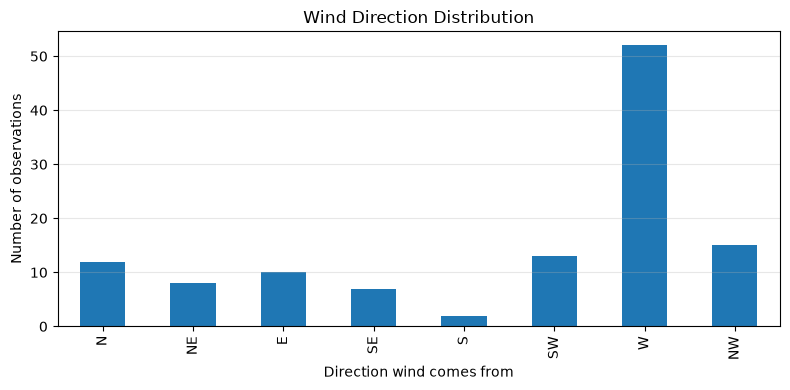

PM25_mean  PM10_mean  Observations
station WindDirection                                    
Dwarka  E                 264.86     433.86             7
        N                 214.70     355.62            10
        NE                140.14     405.33             7
        NW                121.93     318.86            14
        S                 214.00     390.00             2
        SE                206.00     331.71             7
        SW                164.77     342.54            13
        W                 124.92     289.17            52
IGI     E                 218.27     388.14             8
        N                 146.45     343.68            10
        NE                151.08     298.00             8
        NW                102.26     236.54            15
        S                 130.51     309.87             2
        SE                123.32     239.58             7
        SW                130.08     288.29            13
        W                 101.18     237.47            52
NSIT    E                 248.08     389.68             8
        N                 194.00     408.53            11
        NE                163.49     432.27             8
        NW                 91.51     315.24            15
        S                 127.62     495.78             2
        SE                 68.25      96.03             5
        SW                 96.29     296.58            13
        W                  79.99     244.60            52

In [10]:
# 8. WIND DIRECTION SUMMARY

wind_df = combined[
    (combined["WindSpeed"] > 0) &
    (combined["WindDirectionDegrees"].notna())
].copy()

compass = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
wind_df["WindDirection"] = wind_df["WindDirectionDegrees"].apply(
    lambda angle: compass[int((angle + 22.5) % 360 // 45)]
)

# One record per weather timestamp for direction frequency
wind_frequency = (
    wind_df.drop_duplicates("mid_time")["WindDirection"]
    .value_counts()
    .reindex(compass, fill_value=0)
)

print("Wind direction frequency (calm winds excluded):")
display(wind_frequency.rename("Observations").to_frame())

wind_frequency.to_csv(TABLES_DIR / "Wind_Direction_Frequency.csv")

ax = wind_frequency.plot(kind="bar", figsize=(8, 4))
ax.set_title("Wind Direction Distribution")
ax.set_xlabel("Direction wind comes from")
ax.set_ylabel("Number of observations")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "Wind_Direction_Distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

wind_summary = wind_df.groupby(["station", "WindDirection"]).agg(
    PM25_mean=("PM2.5", "mean"),
    PM10_mean=("PM10", "mean"),
    Observations=("PM2.5", "count")
).round(2)

display(wind_summary)
wind_summary.to_csv(TABLES_DIR / "Pollution_by_Wind_Direction.csv")


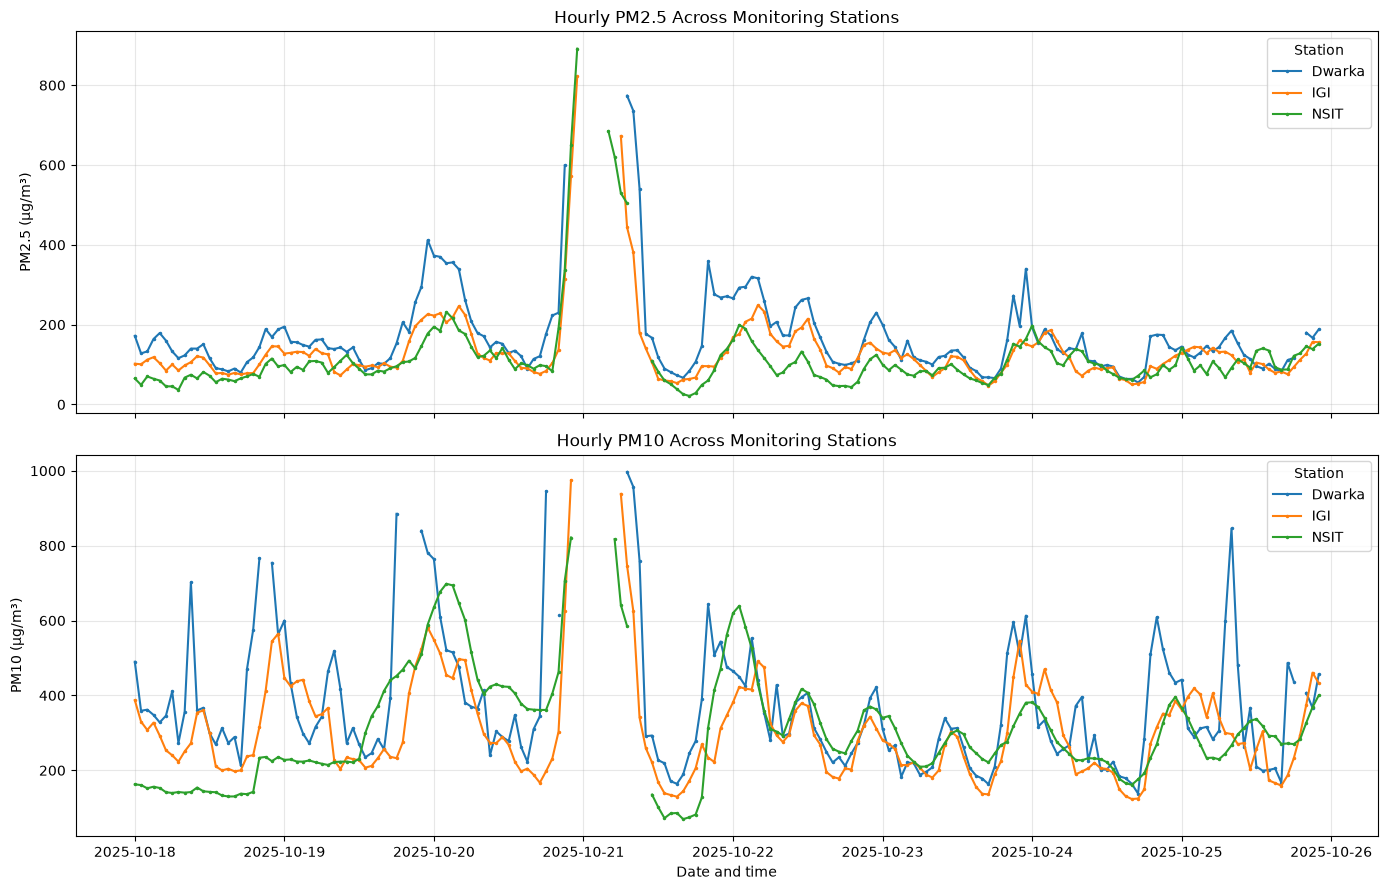

In [11]:
# 9. HOURLY POLLUTION TRENDS

hourly_df = combined.sort_values("from_time")

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

for station in stations:
    part = hourly_df[hourly_df["station"] == station]
    axes[0].plot(part["from_time"], part["PM2.5"], marker=".", ms=3, label=station)
    axes[1].plot(part["from_time"], part["PM10"], marker=".", ms=3, label=station)

axes[0].set_title("Hourly PM2.5 Across Monitoring Stations")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[1].set_title("Hourly PM10 Across Monitoring Stations")
axes[1].set_ylabel("PM10 (µg/m³)")
axes[1].set_xlabel("Date and time")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(title="Station")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "Hourly_Pollution_Trends.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


In [12]:
figure_folder = "../Results/figures"

print("Figures currently saved:\n")

for file in sorted(os.listdir(figure_folder)):
    if file.lower().endswith((".png", ".jpg", ".jpeg", ".pdf")):
        print(file)

Figures currently saved:

Daily_PM10_Trends.png
Daily_PM25_Trends.png
Hourly_Pollution_Trends.png
LULC_Percentage_Distribution.png
Pollutant_Distributions_by_Station.png
Station_Wise_Pollution_Comparison.png
Wind_Direction_Distribution.png


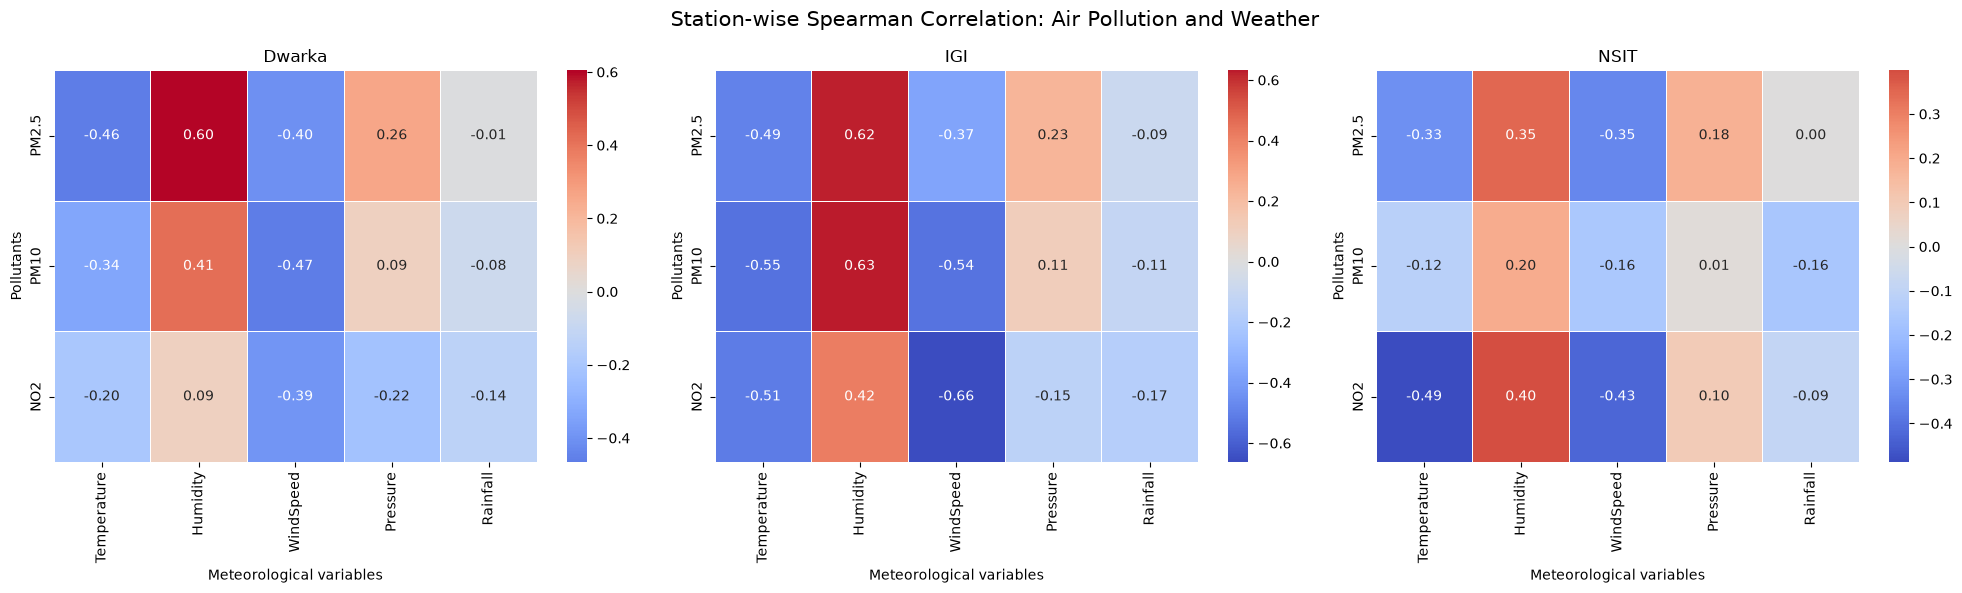

In [13]:

os.makedirs('../Results/figures', exist_ok=True)

pollutants = ['PM2.5', 'PM10', 'NO2']
weather_vars = ['Temperature', 'Humidity', 'WindSpeed', 'Pressure', 'Rainfall']

variables = pollutants + weather_vars

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, station in zip(axes, combined['station'].unique()):

    station_data = combined[combined['station'] == station]

    corr = station_data[variables].corr(method='spearman')

    sns.heatmap(
        corr.loc[pollutants, weather_vars],
        annot=True,
        cmap='coolwarm',
        center=0,
        fmt='.2f',
        linewidths=0.5,
        ax=ax
    )

    ax.set_title(station)
    ax.set_xlabel('Meteorological variables')
    ax.set_ylabel('Pollutants')

plt.suptitle(
    'Station-wise Spearman Correlation: Air Pollution and Weather',
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    '../Results/figures/Pollution_Weather_Correlation_Heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()